## Run initial SUMMA model tests ##

In [1]:
from pathlib import Path

# add auto reload for jupyer magic
%load_ext autoreload
%autoreload 2



In [18]:
# Historic SUMMA assimilation: particle filter, no ESP
from snowda.workflows.run_summa_historic_da import run_summa_historic_da

config_path = Path("../runs/examples/ross_summa_historic_da.yaml").resolve()
run_dir = run_summa_historic_da(config_path)
print("SUMMA run dir:", run_dir)

2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | snowda SUMMA historic DA run starting
2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | Config: /Users/dcasson/GitHub/snowda/runs/examples/ross_summa_historic_da.yaml
2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | Run dir: /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z
2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | Wrote config snapshot: /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z/config.resolved.json
2026-10-22 15:52:14 | INFO     | snowda.snowda.io.summa_ensemble | Creating output directories
2026-10-22 15:52:14 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/SUMMA
2026-10-22 15:52:14 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dc

2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.summa_common | SUMMA statePath: /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z/states
2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | SUMMA outputPath: /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z/summa
2026-10-22 15:52:14 | INFO     | snowda.snowda.workflows.run_summa_historic_da | Starting ensemble run 2012-08-01 00:00:00 to 2014-02-01 00:00:00
2026-10-22 15:52:14 | INFO     | snowda.snowda.adapters.pysumma | SUMMA ensemble starting: 50 members, 10 workers, suffix 2014_02_01
2026-10-22 15:52:14 | INFO     | snowda.snowda.adapters.pysumma | SUMMA member 001 running
2026-10-22 15:52:14 | INFO     | snowda.snowda.adapters.pysumma | SUMMA member 002 running
2026-10-22 15:52:14 | INFO     | snowda.snowda.adapters.pysumma | SUMMA member 003 running
2026-10-22 15:52:14 | INFO     | snowda.snowda.adapters.pysumma | SUMMA member 004 running
20

SUMMA run dir: /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z


In [ ]:
# SUMMA DA (particle filter, then ESP)
from snowda.workflows.run_summa_da import run_summa_da
config_path = Path("../runs/examples/ross_summa_da.yaml").resolve()
run_dir = run_summa_da(config_path)
print("DA run dir:", run_dir)

## Historic ensemble and assimilation states

Gray lines are every historic ensemble member. Dotted lines mark assimilation times, and black dots are the member states at those times. Red stars on the SWE plot are the assimilated basin SWE. Streamflow is mizuRoute discharge from each SUMMA segment, including segments that started from a resampled SUMMA state. The orange line is the gauge.

Plotting /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z


2026-10-22 16:01:16 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z: 50 historic members, 3 states, 0 forecasts
2026-10-22 16:01:22 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/ross_summa_historic_da/20261022T215214Z: 50 historic members, 3 states, 0 forecasts


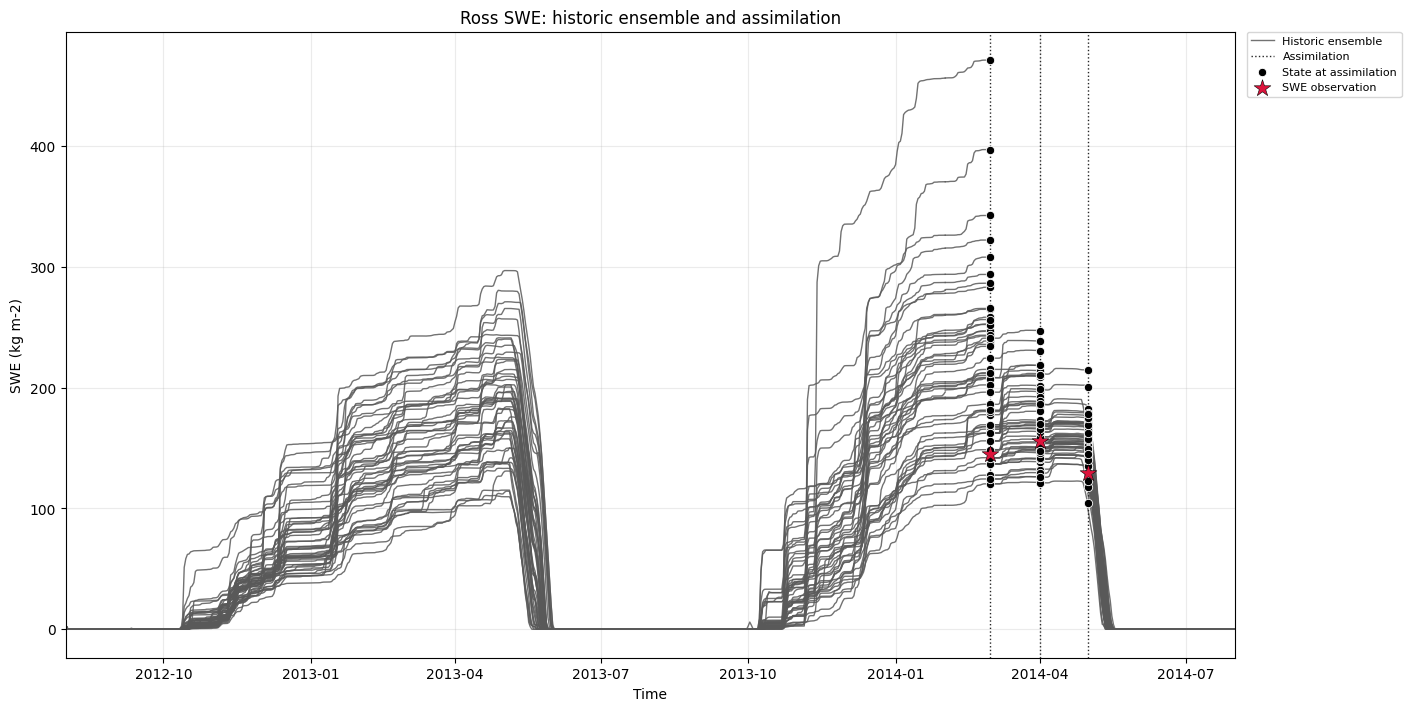

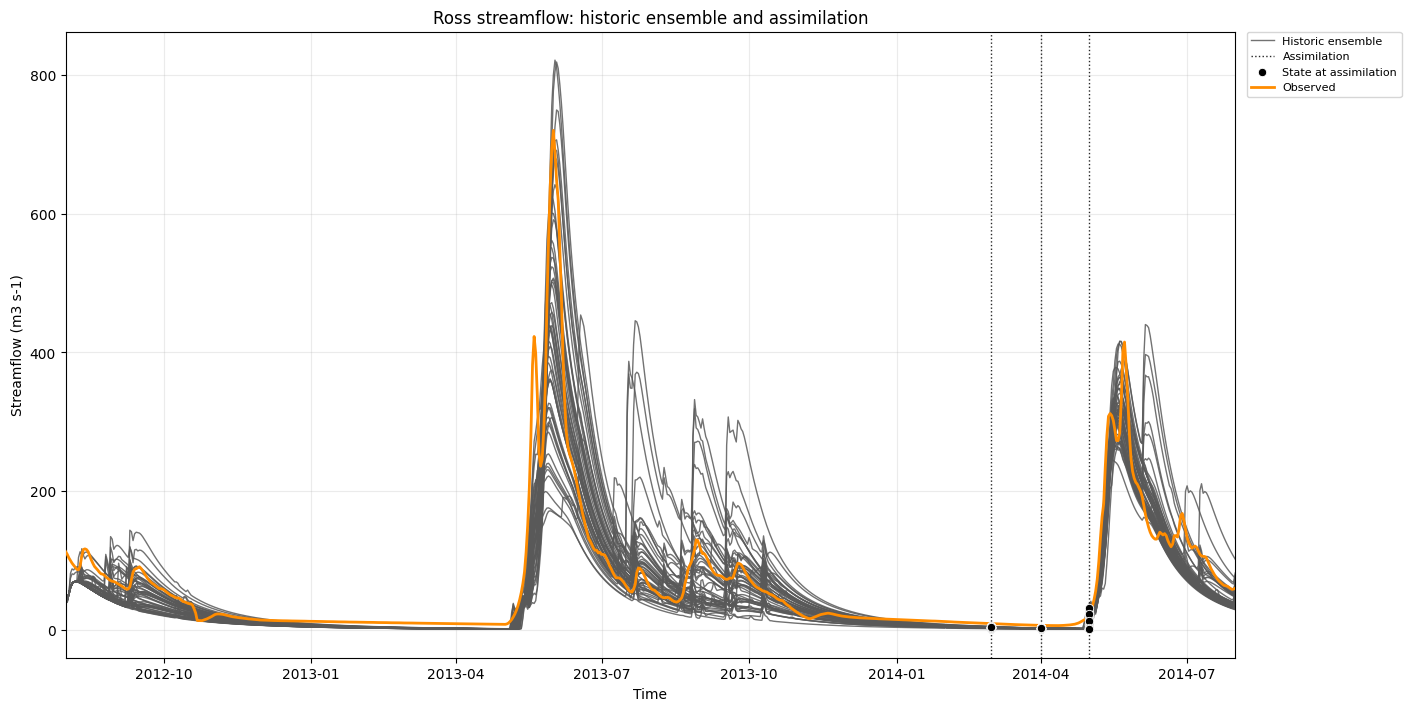

In [19]:
from pathlib import Path

import yaml

from snowda.io.da_traces import load_da_streamflow, load_da_swe
from snowda.io.streamflow import read_streamflow_observations
from snowda.viz.summa_da import plot_da_traces

if "run_dir" in globals() and (Path(run_dir) / "summa").is_dir():
    da_run_dir = Path(run_dir)
else:
    run_root = Path("../outputs/ross_summa_historic_da")
    da_run_dir = max(
        (path for path in run_root.iterdir() if (path / "summa").is_dir()),
        key=lambda path: path.stat().st_mtime,
    )
print("Plotting", da_run_dir)

figure_dir = da_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)

swe = load_da_swe(da_run_dir)
fig, _ax = plot_da_traces(
    swe,
    title="Ross SWE: historic ensemble and assimilation",
)
fig.savefig(figure_dir / "da_swe.png", dpi=150, bbox_inches="tight")

eval_cfg = yaml.safe_load(
    Path("../runs/examples/ross_evaluate_streamflow.yaml").read_text()
)
obs = read_streamflow_observations(eval_cfg["obs_csv"])
flow = load_da_streamflow(da_run_dir)
fig, _ax = plot_da_traces(
    flow,
    obs,
    title="Ross streamflow: historic ensemble and assimilation",
)
fig.savefig(figure_dir / "da_streamflow.png", dpi=150, bbox_inches="tight")